<a href="https://colab.research.google.com/github/Thappatla-Pranitha/PCA/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import numpy as np
import pandas as pd

np.random.seed(23)

# Class 1 data
mu_vec1 = np.array([0, 0, 0])
cov_mat1 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class1_sample = np.random.multivariate_normal(
    mu_vec1, cov_mat1, 20
)

df = pd.DataFrame(
    class1_sample,
    columns=['feature1', 'feature2', 'feature3']
)

df['target'] = 1

# Class 2 data
mu_vec2 = np.array([1, 1, 1])
cov_mat2 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class2_sample = np.random.multivariate_normal(
    mu_vec2, cov_mat2, 20
)

df1 = pd.DataFrame(
    class2_sample,
    columns=['feature1', 'feature2', 'feature3']
)

df1['target'] = 0

# Combine both DataFrames
df = pd.concat([df, df1], ignore_index=True)

# Shuffle the dataset
df = df.sample(40, random_state=23)

# Display first 5 rows
df.head()


,feature1,feature2,feature3,target
18,-0.331617,-1.632386,0.619114,1
23,1.010229,1.437830,2.327788,0
8,0.241106,-0.952510,-0.136267,1
22,1.676860,4.187503,-0.080565,0
33,2.823378,-0.332863,2.637391,0


In [3]:
import plotly.express as px
#y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=df['feature1'], y=df['feature2'], z=df['feature3'],
              color=df['target'].astype('str'))
fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))

fig.show()


In [4]:
# Step 1 - Apply standard scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df.iloc[:,0:3] = scaler.fit_transform(df.iloc[:,0:3])

In [5]:
# Step 2 - Find Covariance Matrix
covariance_matrix = np.cov([df.iloc[:,0],df.iloc[:,1],df.iloc[:,2]])
print('Covariance Matrix:\n', covariance_matrix)


Covariance Matrix:
 [[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


In [6]:

# Step 3 - Finding EV and EVs
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)


eigen_values

array([1.3536065 , 0.94557084, 0.77774573])

In [7]:
eigen_vectors

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442],
       [-0.52848211,  0.72025103,  0.44938304]])

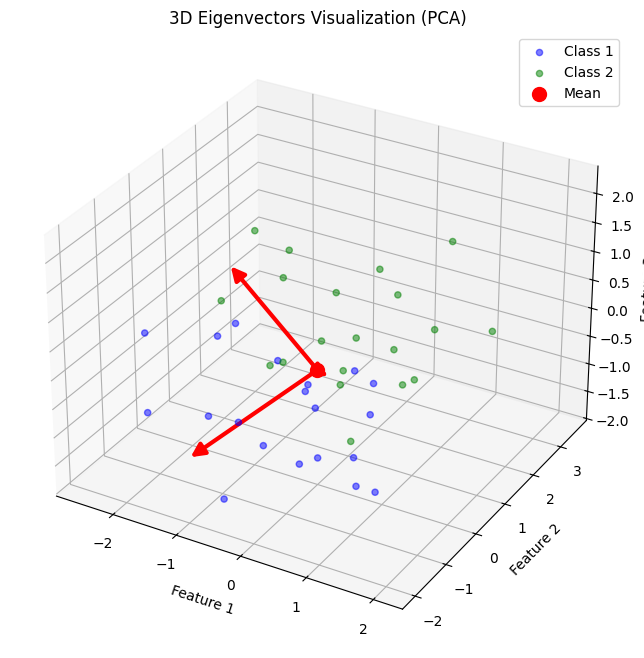

Eigenvalues:
[1.3536065  0.94557084 0.77774573]

Eigenvectors:
[[-0.53875915 -0.69363291  0.47813384]
 [-0.65608325 -0.01057596 -0.75461442]
 [-0.52848211  0.72025103  0.44938304]]


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d import proj3d
from matplotlib.patches import FancyArrowPatch

# Select only feature columns
X = df[['feature1', 'feature2', 'feature3']].values

# Calculate mean
mean = np.mean(X, axis=0)

# Center the data
X_centered = X - mean

# Calculate covariance matrix
cov_mat = np.cov(X_centered, rowvar=False)

# Calculate eigenvalues and eigenvectors
eigen_values, eigen_vectors = np.linalg.eigh(cov_mat)

# Sort eigenvectors by descending eigenvalues
idx = np.argsort(eigen_values)[::-1]
eigen_values = eigen_values[idx]
eigen_vectors = eigen_vectors[:, idx]


# Custom Arrow3D class for modern Matplotlib
class Arrow3D(FancyArrowPatch):

    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):

        xs3d, ys3d, zs3d = self._verts3d

        xs, ys, zs = proj3d.proj_transform(
            xs3d, ys3d, zs3d, self.axes.get_proj()
        )

        self.set_positions(
            (xs[0], ys[0]),
            (xs[1], ys[1])
        )

        return np.min(zs)


# Create 3D plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot Class 1
class1 = df[df['target'] == 1]

ax.scatter(
    class1['feature1'],
    class1['feature2'],
    class1['feature3'],
    color='blue',
    label='Class 1',
    alpha=0.5
)

# Plot Class 2
class2 = df[df['target'] == 0]

ax.scatter(
    class2['feature1'],
    class2['feature2'],
    class2['feature3'],
    color='green',
    label='Class 2',
    alpha=0.5
)

# Plot mean / centroid
ax.scatter(
    mean[0], mean[1], mean[2],
    color='red',
    s=100,
    label='Mean'
)

# Draw eigenvectors
# Scale arrows using square root of eigenvalues
for i in range(3):

    v = eigen_vectors[:, i]
    scale = 2 * np.sqrt(eigen_values[i])

    a = Arrow3D(
        [mean[0], mean[0] + scale * v[0]],
        [mean[1], mean[1] + scale * v[1]],
        [mean[2], mean[2] + scale * v[2]],
        mutation_scale=20,
        lw=3,
        arrowstyle="-|>",
        color="red"
    )

    ax.add_artist(a)

# Labels
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')

ax.set_title('3D Eigenvectors Visualization (PCA)')

ax.legend()

plt.show()


# Display eigenvalues
print("Eigenvalues:")
print(eigen_values)

print("\nEigenvectors:")
print(eigen_vectors)


In [10]:
pc = eigen_vectors[0:2]
pc


array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442]])

In [11]:
transformed_df = np.dot(df.iloc[:,0:3],pc.T)
# 40,3 - 3,2
new_df = pd.DataFrame(transformed_df,columns=['PC1','PC2'])
new_df['target'] = df['target'].values
new_df.head()

,PC1,PC2,target
0,1.726114,0.492511,1
1,-0.220797,-1.441911,0
2,0.688605,0.658084,1
3,-3.367715,-0.254627,0
4,0.227326,-2.669841,0


In [12]:
new_df['target'] = new_df['target'].astype('str')
fig = px.scatter(x=new_df['PC1'],
                 y=new_df['PC2'],
                 color=new_df['target'],
                 color_discrete_sequence=px.colors.qualitative.G10
                )

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))
fig.show()